# Sri Lankan House Rental Price Prediction
## Using Ensemble Learning Techniques

### Project Objective
To predict monthly rental prices of residential properties
in Sri Lanka using machine learning ensemble techniques.

### Data
Rental listings collected manually from ikman.lk (Sri Lankan context).

### Models to be evaluated
1. Decision Tree Regressor
2. Bagging Regressor
3. Random Forest Regressor
4. XGBoost Regressor
5. Stacking Regressor

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

In [6]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, RepeatedKFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, StackingRegressor
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
RANDOM_STATE = 42

DATA_DIR = Path("../data")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import sklearn
import xgboost

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

Pandas version: 3.1.1
NumPy version: 2.5.5
Scikit-learn version: 1.9.1
XGBoost version: 3.4.1


## Step 1 – Load the data
Listings collected manually from ikman.lk.

In [8]:
raw = pd.read_csv(DATA_DIR / "rental_properties_raw.csv")
print("Shape:", raw.shape)
raw.head(10)

Shape: (90, 12)


,Location,District,Type,Bedrooms,Bathrooms,Size_sqft,Furnished,Parking,Garden,Monthly_rent,Note1,Note2
0,Ja-Ela,Gampaha,House,2,1,1300,Yes,Yes,NaN,80000,NaN,NaN
1,Ratmalana,Colombo,House,3,2,1800,No,Yes,NaN,99999,NaN,NaN
2,Marawila,Puttalam,House,3,2,1500,Yes,Yes,NaN,60000,NaN,NaN
3,Piliyandala,Colombo,House,4,3,2000,Yes,Yes,Yes,225000,NaN,NaN
4,Kelaniya,Gampaha,House,4,3,2000,No,NaN,NaN,120000,NaN,NaN
5,Pannipitiya,Colombo,House,4,2,2500,NaN,Yes,NaN,200000,NaN,NaN
6,Malabe,Colombo,House,3,3,1200,Yes,Yes,Yes,250000,NaN,NaN
7,Maharagama,Colombo,Apartment,2,2,1200,Yes,Yes,No,150000,NaN,NaN
8,Dehiwala,Colombo,House,5,6,3200,No,Yes,NaN,325000,front and back yard is that mean there is a ga...,NaN
9,Thalawatugoda,Colombo,House,3,2,1800,No,NaN,No,100000,servant,NaN


In [9]:
print("Missing values per column:")
print(raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

Missing values per column:
Location         0
District         0
Type             0
Bedrooms         0
Bathrooms        0
Size_sqft        0
Furnished        3
Parking          8
Garden          16
Monthly_rent     0
Note1           56
Note2           79
dtype: int64

Duplicate rows: 0


## Step 2 – Data cleaning
- Fix spelling of some locations.
- Missing `Parking` and `Garden` are set to `No` (the ad did not mention them).
- Missing `Furnished` is set to `Unknown`. `semi` becomes `Semi`.
- The free-text notes are turned into 3 yes/no columns: AC, servant room, pool/gym.
- Locations are grouped into area tiers, because there are too many single locations for 90 rows.

In [10]:
df = raw.copy()

# fix spelling
df["Location"] = df["Location"].str.strip().replace({
    "Negambo": "Negombo",
    "Talawatugoda": "Thalawatugoda",
    "Colombo4": "Colombo 4",
    "Kandy city": "Kandy",
})

# notes -> yes/no columns
notes = (df["Note1"].fillna("") + " " + df["Note2"].fillna("")).str.lower()
df["Has_AC"] = notes.str.contains(r"\bac\b").astype(int)
df["Has_Servant_Room"] = notes.str.contains("servant").astype(int)
df["Has_Pool_Gym"] = notes.str.contains("pool|gym").astype(int)

# missing values
df.loc[notes.str.contains("yard"), "Garden"] = "Yes"
df["Furnished"] = df["Furnished"].replace({"semi": "Semi"}).fillna("Unknown")
df["Parking"] = df["Parking"].fillna("No")
df["Garden"] = df["Garden"].fillna("No")

# area tier
prime = ["Colombo 2", "Colombo 3", "Colombo 4", "Colombo 5", "Colombo 6", "Colombo 7"]

def get_area_tier(row):
    if row["Location"] in prime:
        return "Colombo Prime"
    if row["District"] == "Colombo":
        return "Colombo Suburbs"
    if row["District"] in ["Gampaha", "Galle", "Kandy"]:
        return row["District"]
    return "Other Districts"

df["Area_Tier"] = df.apply(get_area_tier, axis=1)

clean = df[["Location", "District", "Area_Tier", "Type", "Bedrooms", "Bathrooms",
            "Size_sqft", "Furnished", "Parking", "Garden",
            "Has_AC", "Has_Servant_Room", "Has_Pool_Gym", "Monthly_rent"]].copy()
for col in ["Bedrooms", "Bathrooms", "Size_sqft", "Monthly_rent"]:
    clean[col] = clean[col].astype(int)

clean.to_csv(DATA_DIR / "rental_properties.csv", index=False)
print("Saved cleaned data:", clean.shape)
clean.head(10)

Saved cleaned data: (90, 14)


,Location,District,Area_Tier,Type,Bedrooms,Bathrooms,Size_sqft,Furnished,Parking,Garden,Has_AC,Has_Servant_Room,Has_Pool_Gym,Monthly_rent
0,Ja-Ela,Gampaha,Gampaha,House,2,1,1300,Yes,Yes,No,0,0,0,80000
1,Ratmalana,Colombo,Colombo Suburbs,House,3,2,1800,No,Yes,No,0,0,0,99999
2,Marawila,Puttalam,Other Districts,House,3,2,1500,Yes,Yes,No,0,0,0,60000
3,Piliyandala,Colombo,Colombo Suburbs,House,4,3,2000,Yes,Yes,Yes,0,0,0,225000
4,Kelaniya,Gampaha,Gampaha,House,4,3,2000,No,No,No,0,0,0,120000
5,Pannipitiya,Colombo,Colombo Suburbs,House,4,2,2500,Unknown,Yes,No,0,0,0,200000
6,Malabe,Colombo,Colombo Suburbs,House,3,3,1200,Yes,Yes,Yes,0,0,0,250000
7,Maharagama,Colombo,Colombo Suburbs,Apartment,2,2,1200,Yes,Yes,No,0,0,0,150000
8,Dehiwala,Colombo,Colombo Suburbs,House,5,6,3200,No,Yes,Yes,0,0,0,325000
9,Thalawatugoda,Colombo,Colombo Suburbs,House,3,2,1800,No,No,No,0,1,0,100000


## Step 3 – Exploratory Data Analysis

In [11]:
print(clean["Type"].value_counts(), "\n")
print(clean["Area_Tier"].value_counts(), "\n")
clean[["Bedrooms", "Bathrooms", "Size_sqft", "Monthly_rent"]].describe()

Type
House        74
Apartment    16
Name: count, dtype: int64 

Area_Tier
Colombo Suburbs    35
Other Districts    17
Galle              13
Gampaha            11
Colombo Prime       7
Kandy               7
Name: count, dtype: int64 



,Bedrooms,Bathrooms,Size_sqft,Monthly_rent
count,90.00,90.00,90.00,90.00
mean,2.89,2.20,"1,793.37","156,172.21"
std,1.02,1.02,"1,031.05","124,128.00"
min,1.00,1.00,300.00,"25,000.00"
25%,2.00,2.00,"1,105.00","70,000.00"
50%,3.00,2.00,"1,600.00","115,000.00"
75%,4.00,3.00,"2,300.00","200,000.00"
max,6.00,6.00,"7,040.00","600,000.00"


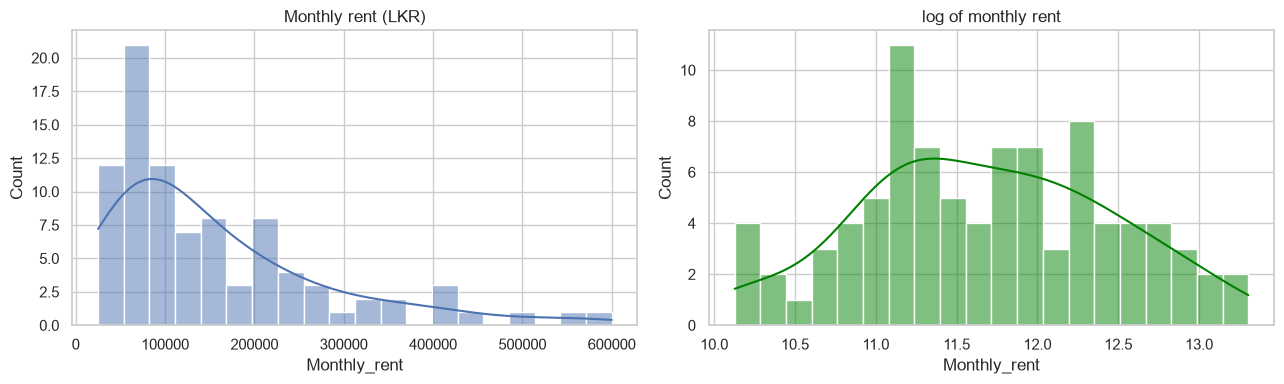

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(clean["Monthly_rent"], bins=20, kde=True, ax=ax[0])
ax[0].set_title("Monthly rent (LKR)")
sns.histplot(np.log1p(clean["Monthly_rent"]), bins=20, kde=True, ax=ax[1], color="green")
ax[1].set_title("log of monthly rent")
plt.tight_layout()
plt.show()

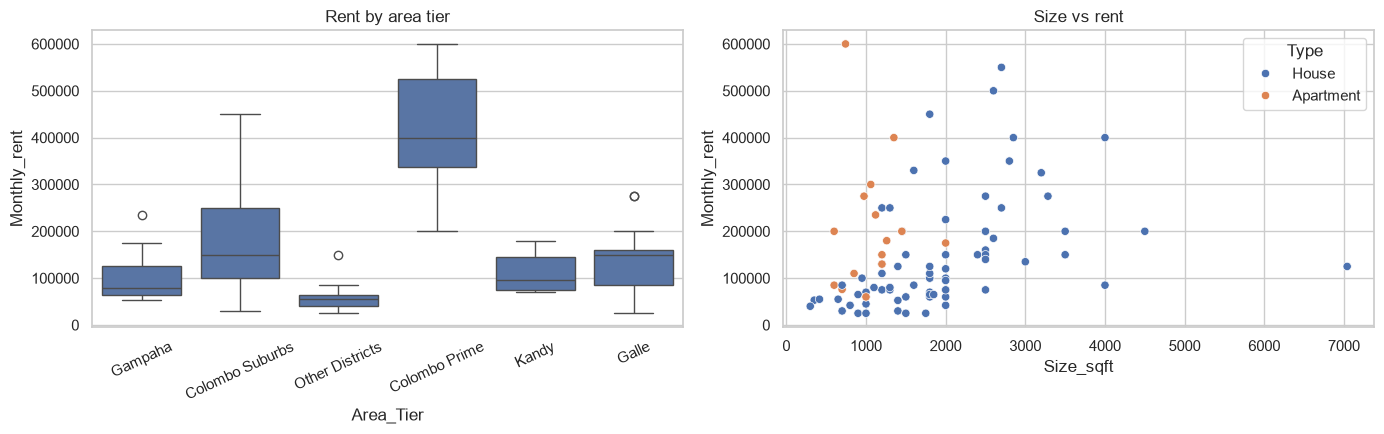

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=clean, x="Area_Tier", y="Monthly_rent", ax=ax[0])
ax[0].set_title("Rent by area tier")
ax[0].tick_params(axis="x", rotation=25)
sns.scatterplot(data=clean, x="Size_sqft", y="Monthly_rent", hue="Type", ax=ax[1])
ax[1].set_title("Size vs rent")
plt.tight_layout()
plt.show()

## Step 4 – Features and train/test split
- Target: `Monthly_rent`. We train on the log of the rent (it is right skewed) and convert the prediction back to LKR.
- 80% of rows for training, 20% for testing.

In [14]:
num_features = ["Bedrooms", "Bathrooms", "Size_sqft", "Has_AC", "Has_Servant_Room", "Has_Pool_Gym"]
cat_features = ["Type", "Area_Tier", "Furnished", "Parking", "Garden"]

X = clean[num_features + cat_features]
y = clean["Monthly_rent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 72
Testing rows: 18


## Step 5 – Build the models
- **Decision Tree** – a single tree.
- **Bagging** – many trees trained on random samples, predictions averaged.
- **Random Forest** – bagging + random features at each split.
- **XGBoost** – trees built one after another, each one fixes the errors of the previous (boosting).
- **Stacking** – Bagging, Random Forest and XGBoost make predictions, then a Ridge model combines them.

In [15]:
def make_pipeline(model):
    # one-hot encode text columns, then the model; rent is predicted on log scale
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", "passthrough", num_features),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def get_xgb():
    return XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                        min_child_weight=2, reg_lambda=5, subsample=0.8,
                        colsample_bytree=0.8, random_state=RANDOM_STATE)

def get_models():
    tree = DecisionTreeRegressor(max_depth=5, min_samples_leaf=2, random_state=RANDOM_STATE)
    bagging = BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                               n_estimators=200, random_state=RANDOM_STATE)
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)
    xgb = get_xgb()
    stacking = StackingRegressor(
        estimators=[
            ("bagging", BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                                         n_estimators=100, random_state=RANDOM_STATE)),
            ("rf", RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE)),
            ("xgb", get_xgb()),
        ],
        final_estimator=Ridge(),
        cv=5,
    )
    return {
        "Decision Tree": make_pipeline(tree),
        "Bagging": make_pipeline(bagging),
        "Random Forest": make_pipeline(rf),
        "XGBoost": make_pipeline(xgb),
        "Stacking": make_pipeline(stacking),
    }

method = {"Decision Tree": "Single model", "Bagging": "Bagging", "Random Forest": "Bagging",
          "XGBoost": "Boosting", "Stacking": "Stacking"}
list(get_models())

['Decision Tree', 'Bagging', 'Random Forest', 'XGBoost', 'Stacking']

## Step 6 – Train and test (80/20 split)

In [16]:
results = []
predictions = {"Actual": y_test.values}

for name, model in get_models().items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append({
        "Model": name,
        "Method": method[name],
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
    })

holdout = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
holdout

,Model,Method,MAE,MSE,RMSE,R2
0,Bagging,Bagging,"45,781.61","5,655,657,510.22","75,204.11",0.66
1,Stacking,Stacking,"51,415.03","6,122,740,772.34","78,247.94",0.63
2,Random Forest,Bagging,"44,251.35","6,496,377,880.04","80,600.11",0.61
3,XGBoost,Boosting,"49,917.23","6,628,753,920.00","81,417.16",0.60
4,Decision Tree,Single model,"64,409.14","9,525,027,409.64","97,596.25",0.43


## Step 7 – Cross-validation
With only 90 rows, one test split can be lucky or unlucky.
So we also run 5-fold cross-validation 3 times (15 rounds per model) and take the average.

In [17]:
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "mse": "neg_mean_squared_error"}

rows = []
for name, model in get_models().items():
    s = cross_validate(model, X, y, cv=cv, scoring=scoring)
    rmse = np.sqrt(-s["test_mse"])
    rows.append({
        "Model": name,
        "Method": method[name],
        "MAE": -s["test_mae"].mean(),
        "MSE": (-s["test_mse"]).mean(),
        "RMSE": rmse.mean(),
        "R2": s["test_r2"].mean(),
        "R2_std": s["test_r2"].std(),
    })
    print("done:", name)

cv_results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
cv_results

done: Decision Tree
done: Bagging
done: Random Forest
done: XGBoost
done: Stacking


,Model,Method,MAE,MSE,RMSE,R2,R2_std
0,XGBoost,Boosting,"53,611.78","7,769,714,756.27","82,746.06",0.48,0.22
1,Stacking,Stacking,"55,026.99","8,029,141,217.66","84,107.97",0.45,0.25
2,Bagging,Bagging,"56,839.03","8,700,189,470.76","86,934.66",0.42,0.25
3,Random Forest,Bagging,"56,876.77","8,911,205,230.85","87,401.15",0.43,0.25
4,Decision Tree,Single model,"70,966.00","11,231,231,725.47","101,267.65",0.20,0.29


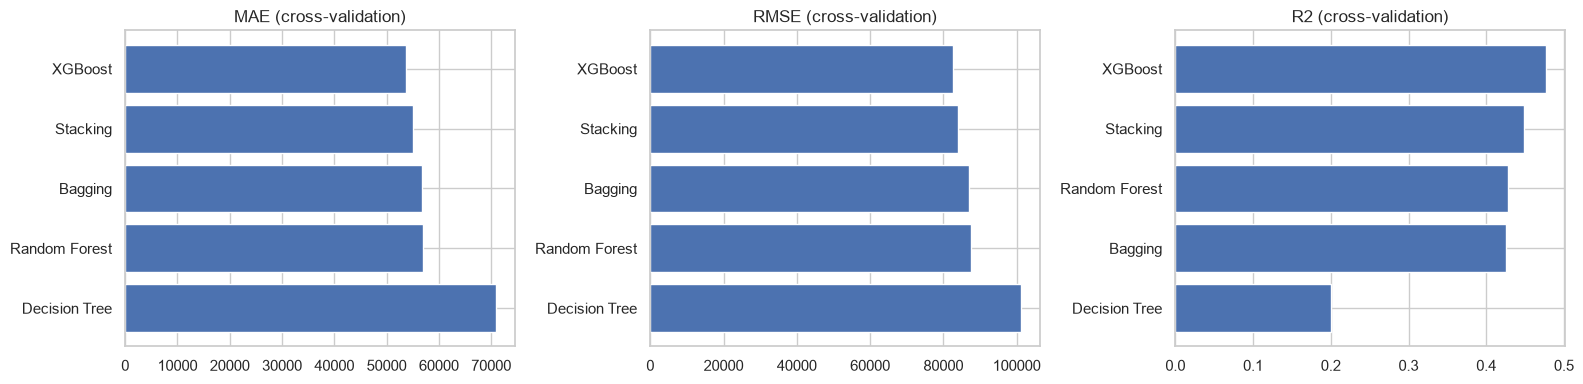

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, metric in zip(ax, ["MAE", "RMSE", "R2"]):
    d = cv_results.sort_values(metric, ascending=(metric != "R2"))
    a.barh(d["Model"], d[metric])
    a.invert_yaxis()
    a.set_title(metric + " (cross-validation)")
plt.tight_layout()
plt.show()

## Step 8 – Random Forest vs XGBoost

,Model,Method,MAE,MSE,RMSE,R2,R2_std
0,XGBoost,Boosting,"53,611.78","7,769,714,756.27","82,746.06",0.48,0.22
3,Random Forest,Bagging,"56,876.77","8,911,205,230.85","87,401.15",0.43,0.25


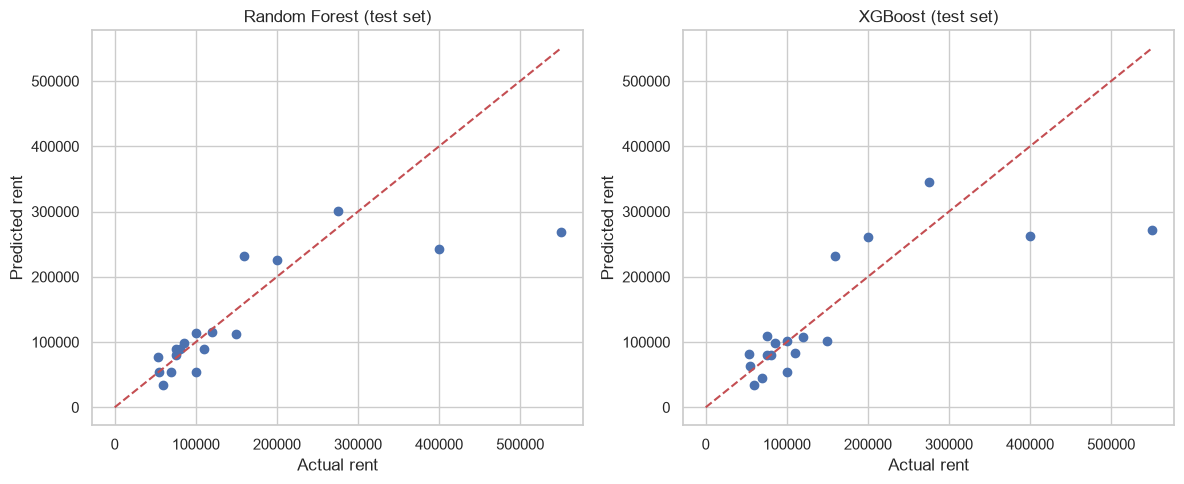

In [19]:
rf_vs_xgb = cv_results[cv_results["Model"].isin(["Random Forest", "XGBoost"])]
display(rf_vs_xgb)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, name in zip(ax, ["Random Forest", "XGBoost"]):
    a.scatter(predictions["Actual"], predictions[name])
    top = max(predictions["Actual"].max(), predictions[name].max())
    a.plot([0, top], [0, top], "r--")
    a.set_title(f"{name} (test set)")
    a.set_xlabel("Actual rent")
    a.set_ylabel("Predicted rent")
plt.tight_layout()
plt.show()

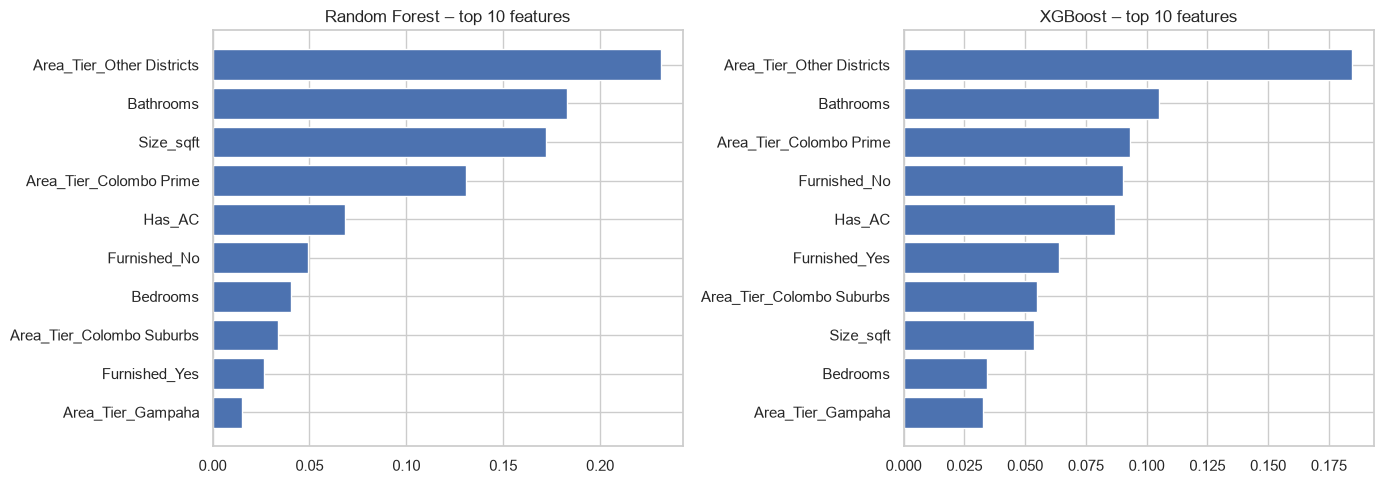

In [20]:
# which features matter most? (trained on all data)
rf_full = get_models()["Random Forest"].fit(X, y)
xgb_full = get_models()["XGBoost"].fit(X, y)

imp = []
for name, m in [("Random Forest", rf_full), ("XGBoost", xgb_full)]:
    pipe = m.regressor_
    names = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    for f, v in zip(names, pipe.named_steps["model"].feature_importances_):
        imp.append({"Model": name, "Feature": f, "Importance": v})
importance = pd.DataFrame(imp)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, name in zip(ax, ["Random Forest", "XGBoost"]):
    d = importance[importance["Model"] == name].nlargest(10, "Importance")
    a.barh(d["Feature"], d["Importance"])
    a.invert_yaxis()
    a.set_title(name + " – top 10 features")
plt.tight_layout()
plt.show()

## Step 9 – Bagging vs Stacking

,Model,Method,MAE,MSE,RMSE,R2,R2_std
1,Stacking,Stacking,"55,026.99","8,029,141,217.66","84,107.97",0.45,0.25
2,Bagging,Bagging,"56,839.03","8,700,189,470.76","86,934.66",0.42,0.25


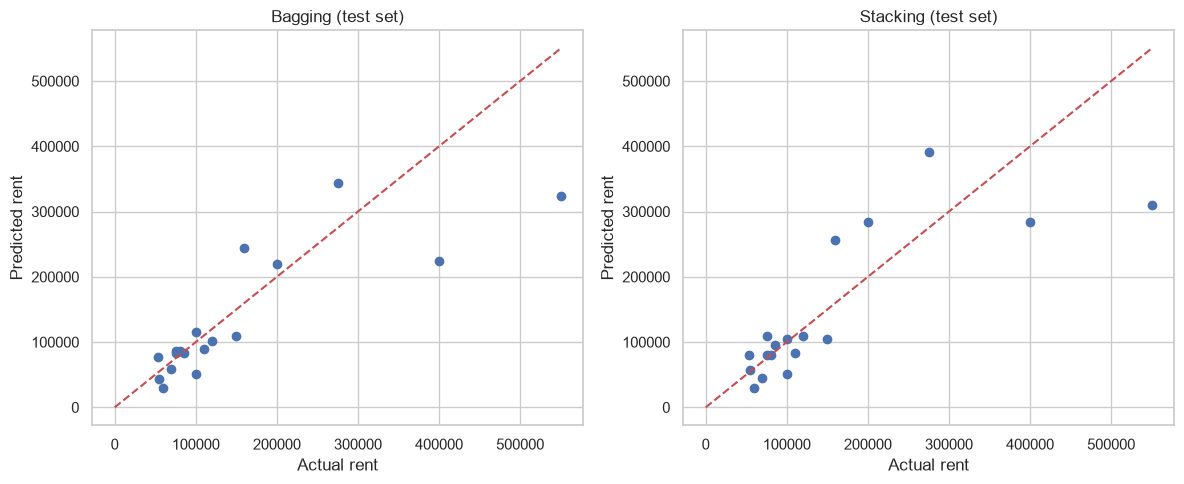

In [21]:
bag_vs_stack = cv_results[cv_results["Model"].isin(["Bagging", "Stacking"])]
display(bag_vs_stack)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, name in zip(ax, ["Bagging", "Stacking"]):
    a.scatter(predictions["Actual"], predictions[name])
    top = max(predictions["Actual"].max(), predictions[name].max())
    a.plot([0, top], [0, top], "r--")
    a.set_title(f"{name} (test set)")
    a.set_xlabel("Actual rent")
    a.set_ylabel("Predicted rent")
plt.tight_layout()
plt.show()

## Step 10 – Save models and results (used by the dashboard)

In [22]:
for name, model in get_models().items():
    model.fit(X, y)
    joblib.dump(model, MODEL_DIR / (name.lower().replace(" ", "_") + ".joblib"))

cv_results.to_csv(MODEL_DIR / "cv_results.csv", index=False)
holdout.to_csv(MODEL_DIR / "holdout_results.csv", index=False)
importance.to_csv(MODEL_DIR / "feature_importance.csv", index=False)

test_table = X_test.reset_index(drop=True).copy()
for k, v in predictions.items():
    test_table[k] = v
test_table.to_csv(MODEL_DIR / "test_predictions.csv", index=False)

with open(MODEL_DIR / "info.json", "w") as f:
    json.dump({"rows": len(clean), "train_rows": len(X_train), "test_rows": len(X_test)}, f)

print(sorted(p.name for p in MODEL_DIR.iterdir()))

['bagging.joblib', 'cv_results.csv', 'decision_tree.joblib', 'feature_importance.csv', 'holdout_results.csv', 'info.json', 'random_forest.joblib', 'stacking.joblib', 'test_predictions.csv', 'xgboost.joblib']


## Conclusion
(Write your own conclusion here after reading the results.)

Points to cover:
1. Which model had the best RMSE and R²?
2. Did the ensemble models beat the single Decision Tree?
3. Random Forest vs XGBoost – which is better on this data?
4. Bagging vs Stacking – which is better?
5. Limitations: small dataset, asking prices from ikman.lk, no exact location.